# 1. A COSMIC population of white dwarf + main-sequence binaries

Stage 1 of the forward model. Draw zero-age binaries from the Moe & Di Stefano (2017)
correlated distributions, give them a constant star formation rate over 10 Gyr, evolve
them with COSMIC (BSE), and keep the systems that are a **detached WD + MS pair today**.

```
[COSMIC population]  ->  Galaxy placement  ->  Gaia selection  ->  compare to DR3 / DR4
```

The science question this stage sets up: Gaia DR3 found about 3,200 WD + MS astrometric
binaries at P = 100-1000 d (Shahaf et al. 2024). Standard binary evolution predicts
that range should be nearly empty, because common envelope evolution shrinks orbits to
days and stable mass transfer leaves them wider. How a model fills that window is a
direct test of common envelope and AGB mass-transfer physics.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

In [2]:
from popsynth import population, analysis
from popsynth.bse_defaults import default_bse_dict

## A small run from scratch

`population.build` runs all of stage 1. A few thousand zero-age binaries take about
20 seconds on two cores. The returned table is oriented as MS / WD whichever star became
the white dwarf, and carries the total stellar mass formed, which is needed later for
absolute counts.

In [3]:
demo = population.build(3000, seed=42, nproc=2)
print(f"{len(demo)} present-day WD+MS systems from 3000 zero-age binaries")
print(f"stellar mass formed to make them: {demo.attrs['mass_formed']:.3g} Msun")
demo[["m_ms", "m_wd", "porb", "ecc", "t_cool", "age", "porb_zams", "had_ce"]].head()

489 present-day WD+MS systems from 3000 zero-age binaries
stellar mass formed to make them: 2e+04 Msun


,m_ms,m_wd,porb,ecc,t_cool,age,porb_zams,had_ce
bin_num,,,,,,,,
7,1.027631,0.773654,2.729166e+00,0.000000,3068.349813,3370.551002,882.907831,True
8,0.859389,0.613860,3.107828e+04,0.211587,66.616091,1917.290430,11139.311414,False
12,0.464805,0.569372,5.944637e-01,0.000000,4494.597001,5426.433743,207.390343,True
18,0.244730,0.602776,1.752867e+06,0.454177,4645.394382,7446.819919,402028.514000,False
28,0.856776,1.031631,2.861288e+06,0.520956,916.678917,965.821350,106770.896630,False


The physics knobs are COSMIC's BSE flags. The defaults come from COSMIC's own
settings file; anything can be overridden by keyword, e.g. `population.build(..., alpha1=[5.0, 5.0])`.

In [4]:
bse = default_bse_dict()
{k: bse[k] for k in ["alpha1", "lambdaf", "qcflag", "kickflag", "wdflag", "ifflag"]}

{'alpha1': [1.0, 1.0],
 'lambdaf': 0.0,
 'qcflag': 5,
 'kickflag': 5,
 'wdflag': 1,
 'ifflag': 1}

## The cached production populations

Two variants were run from **the same 60,000 zero-age binaries** (seed 11), differing
only in common envelope efficiency:

| tag | alpha1 | meaning |
| --- | --- | --- |
| `fiducial` | 1.0 | COSMIC default |
| `alpha5` | 5.0 | very efficient envelope ejection |

Regenerate with `python scripts/run_population.py --tag alpha5 --alpha 5.0 --n 60000 --seed 11` (about 3 minutes each).

In [5]:
pops = {t: analysis.load_population(t) for t in ["fiducial", "alpha5"]}
pd.DataFrame({
    t: {
        "WD+MS systems": len(p),
        "fraction with P = 100-1000 d": ((p.porb > 100) & (p.porb < 1000)).mean(),
        "fraction that went through CE": p.had_ce.mean(),
        "median WD mass [Msun]": p.m_wd.median(),
    } for t, p in pops.items()
}).round(3)

,fiducial,alpha5
WD+MS systems,9589.000,10667.000
fraction with P = 100-1000 d,0.007,0.047
fraction that went through CE,0.289,0.360
median WD mass [Msun],0.614,0.611


## Where the orbits end up

Each point is a present-day WD + MS binary: its zero-age period against today's period.
Systems that went through a common envelope (red) drop by orders of magnitude; systems
that never interacted (grey) move up slightly as the WD progenitor loses mass. The grey
band is Gaia DR3's astrometric window.

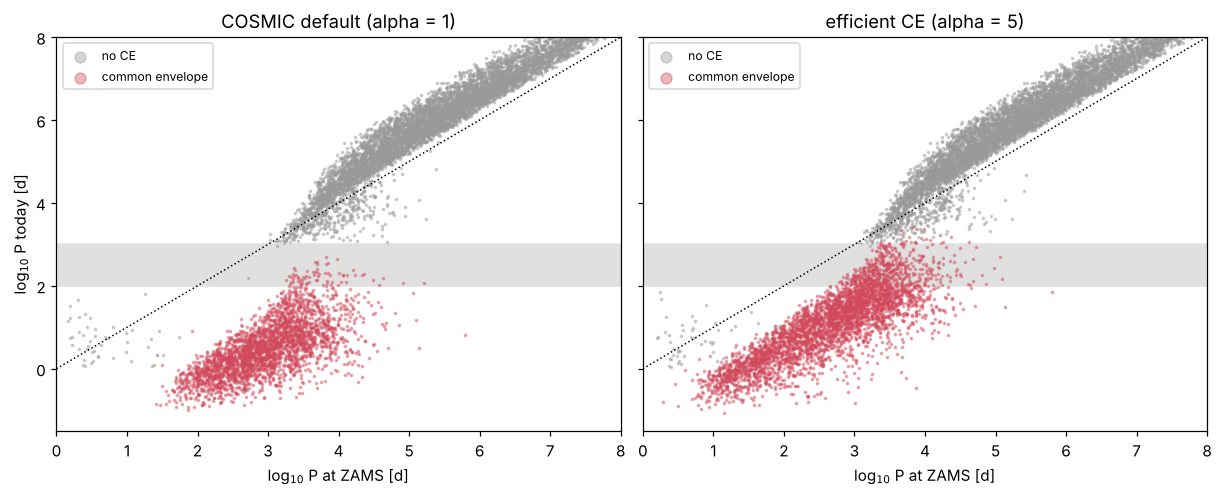

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, constrained_layout=True)
for ax, (t, p) in zip(axes, pops.items()):
    for ce, c, lab in [(False, "0.6", "no CE"), (True, "#d1495b", "common envelope")]:
        s = p[p.had_ce == ce]
        ax.scatter(np.log10(s.porb_zams), np.log10(s.porb), s=2, alpha=0.4, color=c, label=lab, rasterized=True)
    ax.axhspan(2, 3, color="0.88", zorder=0)
    ax.plot([0, 8], [0, 8], "k:", lw=1)
    ax.set_xlim(0, 8); ax.set_ylim(-1.5, 8)
    ax.set_xlabel("log$_{10}$ P at ZAMS [d]")
    ax.set_title(analysis.LABELS[t])
    ax.legend(markerscale=5, fontsize=8, loc="upper left")
axes[0].set_ylabel("log$_{10}$ P today [d]")
plt.show()

With alpha = 1, almost nothing lands in the grey band: the CE products are too tight and
the non-interacting systems too wide. Raising alpha to 5 lets CE survivors stay wider and
partly fills the window. Whether that matches Gaia's period *distribution*, and not just
its occupancy, is the question for notebook 3.

Next: [02_galaxy_and_gaia_selection.ipynb](02_galaxy_and_gaia_selection.ipynb).